# Minor Project 3: Monthly Expense and Spending Pattern Analysis

## Problem Statement
Individuals often track expenses but struggle to understand spending patterns
and control unnecessary costs.
This project analyzes personal expense data to identify trends and spending behavior.

## Objectives
- Analyze monthly expense data
- Identify high-spending categories
- Understand daily and category-wise expense patterns
- Visualize spending behavior

## Tools and Libraries Used
- Python
- Pandas for data handling
- Matplotlib and Seaborn for visualization

In [2]:
# Import Required Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.show()

## Step 1: Load the Expense Dataset
The dataset is loaded using Pandas from a file stored
in the same folder as this notebook.

In [3]:
# Read Dataset
file_path = "4876474-Supermarket_Analysis_Dataset.xlsx"
df = pd.read_excel(file_path)

In [4]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05 00:00:00,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.82,80.22,2019-03-08 00:00:00,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03 00:00:00,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.288,489.048,2019-01-27 00:00:00,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08 00:00:00,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3


## Step 2: Inspect Dataset Structure
Understand column names, data types, and dataset size.

In [5]:
# Inspect Data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               10000 non-null  object 
 1   Branch                   10000 non-null  object 
 2   City                     10000 non-null  object 
 3   Customer type            10000 non-null  object 
 4   Gender                   10000 non-null  object 
 5   Product line             10000 non-null  object 
 6   Unit price               10000 non-null  object 
 7   Quantity                 10000 non-null  object 
 8   Tax 5%                   10000 non-null  object 
 9   Sales                    10000 non-null  object 
 10  Date                     10000 non-null  object 
 11  Time                     10000 non-null  object 
 12  Payment                  10000 non-null  object 
 13  cogs                     10000 non-null  float64
 14  gross margin percentage

In [6]:
df.describe()

,cogs,gross margin percentage,gross income,Rating
count,10000.000000,1.000000e+03,1000.000000,1000.00000
mean,171.468972,4.761905e+00,15.379369,6.97270
std,165.568805,8.886228e-16,11.708825,1.71858
min,4.360000,4.761905e+00,0.508500,4.00000
25%,62.065000,4.761905e+00,5.924875,5.50000
50%,117.685000,4.761905e+00,12.088000,7.00000
75%,221.605000,4.761905e+00,22.445250,8.50000
max,1760.890000,4.761905e+00,49.650000,10.00000


In [7]:
df.columns

Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Sales', 'Date',
       'Time', 'Payment', 'cogs', 'gross margin percentage', 'gross income',
       'Rating'],
      dtype='object')

## Step 3: Data Cleaning and Preprocessing
Check for missing values and handle them appropriately.

In [8]:
# Handle Missing Values
df.isnull().sum()

Invoice ID                    0
Branch                        0
City                          0
Customer type                 0
Gender                        0
Product line                  0
Unit price                    0
Quantity                      0
Tax 5%                        0
Sales                         0
Date                          0
Time                          0
Payment                       0
cogs                          0
gross margin percentage    9000
gross income               9000
Rating                     9000
dtype: int64

In [9]:
df.fillna(0)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,2019-01-05 00:00:00,13:08:00,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.82,80.22,2019-03-08 00:00:00,10:29:00,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,2019-03-03 00:00:00,13:23:00,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.288,489.048,2019-01-27 00:00:00,20:33:00,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2019-02-08 00:00:00,10:37:00,Ewallet,604.17,4.761905,30.2085,5.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,2023-11-19 00:00:00,Alicia Davis,Dover,Delaware,East,United States,Home & Furniture,Storage,Storage Rack,1,308.65,308.65,89.57,0.000000,0.0000,0.0
9996,9997,2024-11-16 00:00:00,Mario Nichols,Burlington,Vermont,East,United States,Home & Furniture,Bedding,Tempur-Pedic Mattress,1,973.24,973.24,193.48,0.000000,0.0000,0.0
9997,9998,2023-02-08 00:00:00,Ruth Bailey,San Diego,California,West,United States,Clothing & Apparel,Women's Wear,Old Navy Dress,1,94.77,94.77,25.72,0.000000,0.0000,0.0
9998,9999,2023-04-16 00:00:00,Mackenzie Skinner,Pittsburgh,Pennsylvania,East,United States,Accessories,Wearable Accessories,Sunglasses,3,226.42,679.26,300.17,0.000000,0.0000,0.0


## Step 4: Date Processing
Convert date column to datetime for trend analysis.

In [10]:
df["Date"] = pd.to_datetime(df["Date"])

## Step 5: Category-wise Expense Analysis
Analyze total and average expenses by category.

In [11]:
print(df["Sales"].dtype)

object


In [12]:
df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

In [13]:
print(df["Sales"].isna().sum())

9000


In [14]:
df.groupby("Product line")["Sales"].agg(["sum", "mean"])

,sum,mean
Product line,,
Centre,0.0000,NaN
East,0.0000,NaN
Electronic accessories,54337.5315,319.632538
Fashion accessories,54305.8950,305.089298
Food and beverages,56144.8440,322.671517
Health and beauty,49193.7390,323.643020
Home and lifestyle,53861.9130,336.636956
South,0.0000,NaN
Sports and travel,55122.8265,332.065220


## Step 6: Expense Trend Over Time
Analyze how expenses change over time.

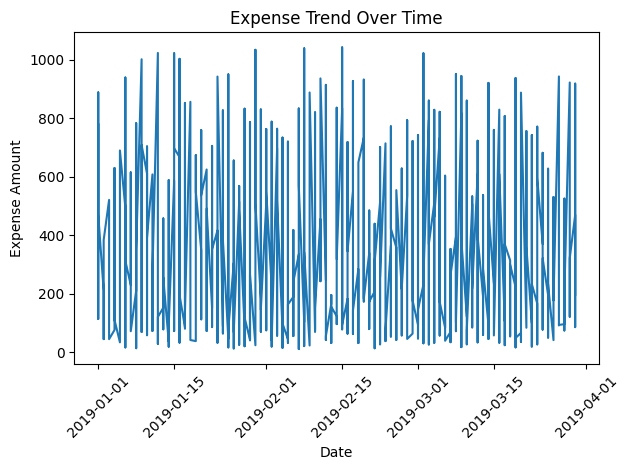

In [15]:
# Line Plot (Expense Trend)
df_sorted = df.sort_values("Date")

plt.figure()
plt.plot(df_sorted["Date"], df_sorted["Sales"])
plt.xlabel("Date")
plt.ylabel("Expense Amount")
plt.title("Expense Trend Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 7: Category-wise Spending Visualization

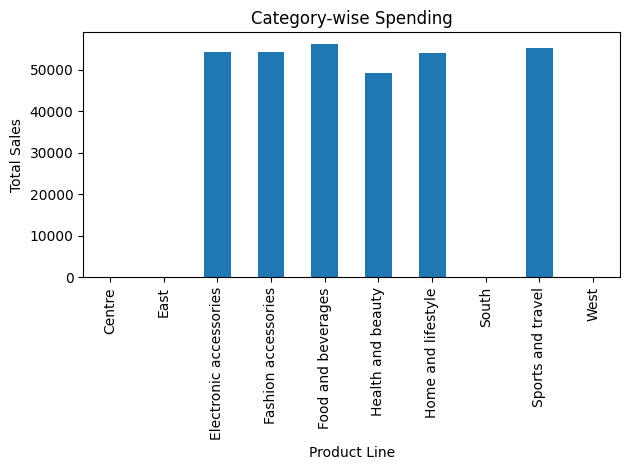

In [16]:
# Bar Chart / Pie Chart
plt.figure()
df.groupby("Product line")["Sales"].sum().plot(kind="bar")
plt.xlabel("Product Line")
plt.ylabel("Total Sales")
plt.title("Category-wise Spending")
plt.tight_layout()
plt.show()

## Step 8: Expense Variability and Outlier Identification

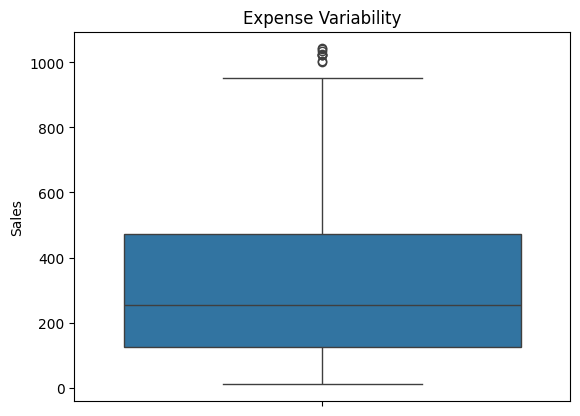

In [17]:
# Box Plot
plt.figure()
sns.boxplot(y=df["Sales"])
plt.title("Expense Variability")
plt.show()

## Step 9: Key Findings and Recommendations
- Certain categories contribute significantly to total expenses.
- Expense trends reveal periods of high spending.
- Outliers indicate unusually high expenses that may require control.
- These insights can help individuals manage budgets more effectively.